# Student Performance Prediction System using Machine Learning
**Objective:** Identify students at risk of failing so that teachers can take early corrective action.

**Flow:** Data Collection → Preprocessing → EDA → Feature Selection → Model Training → Testing → Prediction → Evaluation

## 1. Import Libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

## 2. Data Collection

In [2]:
import os
for p in ["../dataset/student_performance.csv", "dataset/student_performance.csv", "student_performance.csv"]:
    if os.path.exists(p):
        DATA_PATH = p
        break
else:
    raise FileNotFoundError("student_performance.csv not found")

df = pd.read_csv(DATA_PATH)
print("Loaded from:", DATA_PATH)
df.head()

Loaded from: ../dataset/student_performance.csv


,Student_ID,Study_Hours,Attendance,Previous_Marks,Assignments,Internal_Marks,Final_Result
0,STU0001,3.3,51.1,48.3,73.8,65.8,Pass
1,STU0002,7.6,72.5,47.3,83.7,84.4,Pass
2,STU0003,6.0,92.4,93.4,40.0,80.8,Pass
3,STU0004,5.0,83.9,47.5,70.0,32.3,Pass
4,STU0005,1.7,88.4,49.0,65.7,31.9,Pass


In [3]:
df.shape


(1000, 7)

In [4]:
df.columns

Index(['Student_ID', 'Study_Hours', 'Attendance', 'Previous_Marks',
       'Assignments', 'Internal_Marks', 'Final_Result'],
      dtype='str')

In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 7 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Student_ID      1000 non-null   str    
 1   Study_Hours     1000 non-null   float64
 2   Attendance      1000 non-null   float64
 3   Previous_Marks  1000 non-null   float64
 4   Assignments     1000 non-null   float64
 5   Internal_Marks  1000 non-null   float64
 6   Final_Result    1000 non-null   str    
dtypes: float64(5), str(2)
memory usage: 54.8 KB


In [6]:
df.isnull().sum()

Student_ID        0
Study_Hours       0
Attendance        0
Previous_Marks    0
Assignments       0
Internal_Marks    0
Final_Result      0
dtype: int64

In [7]:
df.duplicated().sum()

np.int64(0)

In [8]:
df.describe()

,Study_Hours,Attendance,Previous_Marks,Assignments,Internal_Marks
count,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000
mean,4.177100,70.421700,65.168300,59.229900,59.528600
std,2.191759,17.532111,20.348123,22.919134,22.944937
min,0.500000,40.200000,30.000000,20.100000,20.000000
25%,2.275000,54.475000,48.275000,39.375000,39.625000
50%,4.200000,71.100000,65.000000,58.750000,59.550000
75%,6.100000,85.625000,83.125000,79.000000,79.225000
max,8.000000,100.000000,99.800000,100.000000,99.800000


In [9]:
df["Final_Result"].value_counts()

Final_Result
Pass    913
Fail     87
Name: count, dtype: int64

## 3. Data Preprocessing
Remove duplicates and missing values, convert Pass/Fail to 1/0, drop the ID column.

In [10]:
df["Final_Result"].value_counts(normalize=True) * 100

Final_Result
Pass    91.3
Fail     8.7
Name: proportion, dtype: float64

In [11]:
df_clean = df.copy()

In [12]:
df_clean = df_clean.drop_duplicates()

print("Duplicate records removed successfully!")
print("Dataset shape:", df_clean.shape)

Duplicate records removed successfully!
Dataset shape: (1000, 7)


In [13]:
df_clean.isnull().sum()

Student_ID        0
Study_Hours       0
Attendance        0
Previous_Marks    0
Assignments       0
Internal_Marks    0
Final_Result      0
dtype: int64

In [14]:
df_clean = df_clean.dropna()

In [15]:
df_clean["Final_Result"] = df_clean["Final_Result"].map({
    "Pass": 1,
    "Fail": 0
})

In [16]:
df_clean["Final_Result"].value_counts()

Final_Result
1    913
0     87
Name: count, dtype: int64

In [17]:
df_ml = df_clean.drop("Student_ID", axis=1)

df_ml.head()

,Study_Hours,Attendance,Previous_Marks,Assignments,Internal_Marks,Final_Result
0,3.3,51.1,48.3,73.8,65.8,1
1,7.6,72.5,47.3,83.7,84.4,1
2,6.0,92.4,93.4,40.0,80.8,1
3,5.0,83.9,47.5,70.0,32.3,1
4,1.7,88.4,49.0,65.7,31.9,1


In [18]:
print(df_ml.shape)
print(df_ml.isnull().sum())

(1000, 6)
Study_Hours       0
Attendance        0
Previous_Marks    0
Assignments       0
Internal_Marks    0
Final_Result      0
dtype: int64


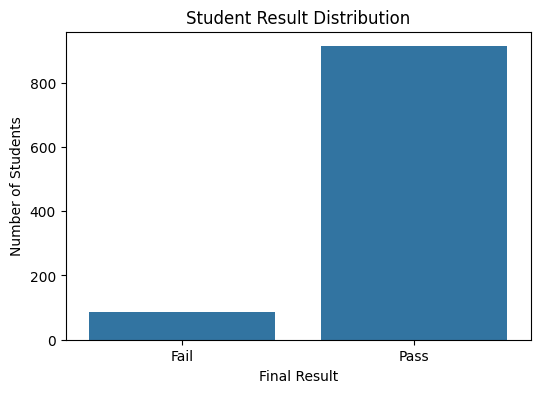

In [19]:
plt.figure(figsize=(6, 4))
sns.countplot(x="Final_Result", data=df_clean)

plt.title("Student Result Distribution")
plt.xlabel("Final Result")
plt.ylabel("Number of Students")
plt.xticks([0, 1], ["Fail", "Pass"])

plt.show()

## 4. Exploratory Data Analysis (EDA)

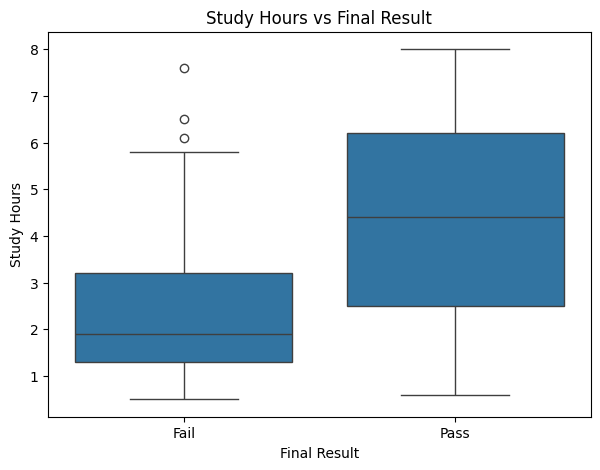

In [20]:
plt.figure(figsize=(7, 5))
sns.boxplot(x="Final_Result", y="Study_Hours", data=df_clean)

plt.title("Study Hours vs Final Result")
plt.xlabel("Final Result")
plt.ylabel("Study Hours")

plt.xticks([0, 1], ["Fail", "Pass"])

plt.show()

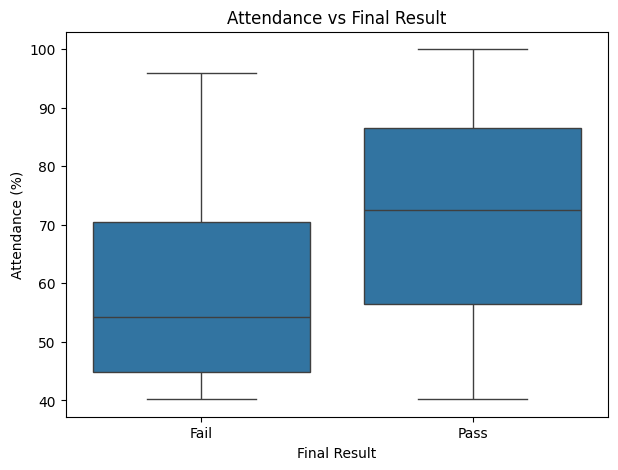

In [21]:
plt.figure(figsize=(7, 5))
sns.boxplot(x="Final_Result", y="Attendance", data=df_clean)

plt.title("Attendance vs Final Result")
plt.xlabel("Final Result")
plt.ylabel("Attendance (%)")

plt.xticks([0, 1], ["Fail", "Pass"])

plt.show()

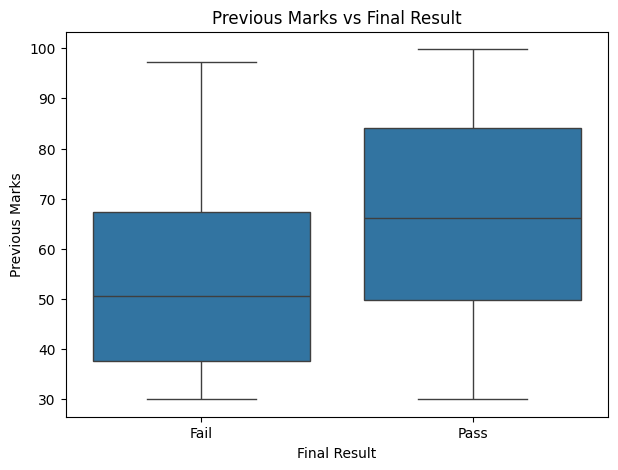

In [22]:
plt.figure(figsize=(7, 5))
sns.boxplot(x="Final_Result", y="Previous_Marks", data=df_clean)

plt.title("Previous Marks vs Final Result")
plt.xlabel("Final Result")
plt.ylabel("Previous Marks")

plt.xticks([0, 1], ["Fail", "Pass"])

plt.show()

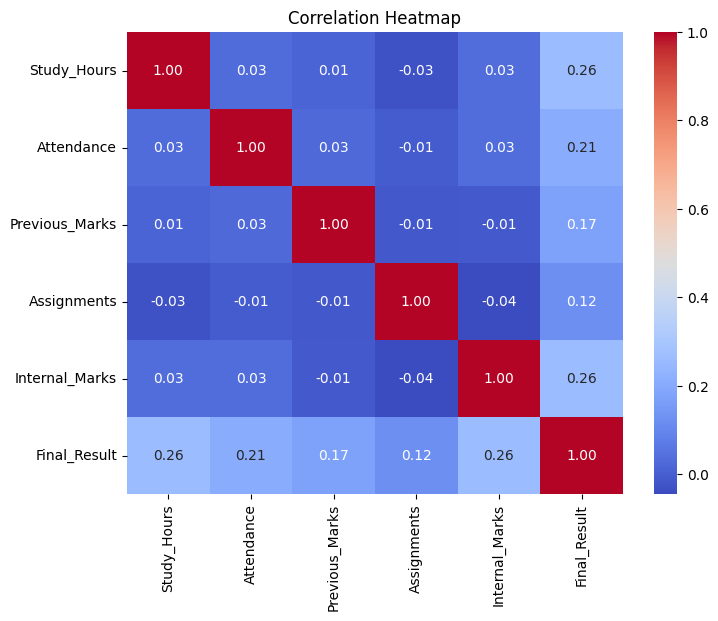

In [23]:
plt.figure(figsize=(8, 6))

sns.heatmap(
    df_ml.corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Heatmap")

plt.show()

In [24]:
X = df_ml.drop("Final_Result", axis=1)
y = df_ml["Final_Result"]

print("Input Features:")
print(X.columns.tolist())

print("\nTarget Variable:")
print(y.name)

Input Features:
['Study_Hours', 'Attendance', 'Previous_Marks', 'Assignments', 'Internal_Marks']

Target Variable:
Final_Result


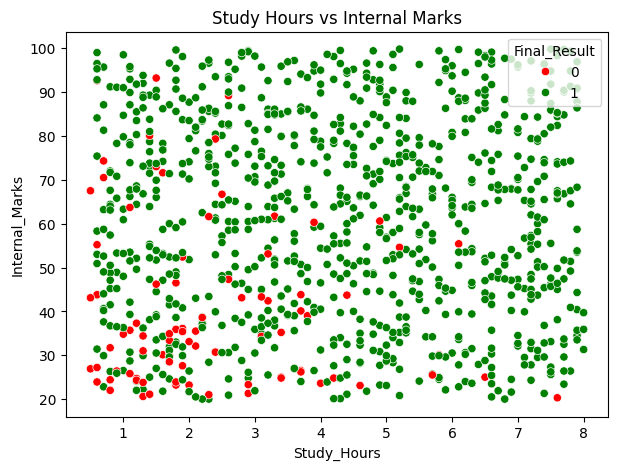

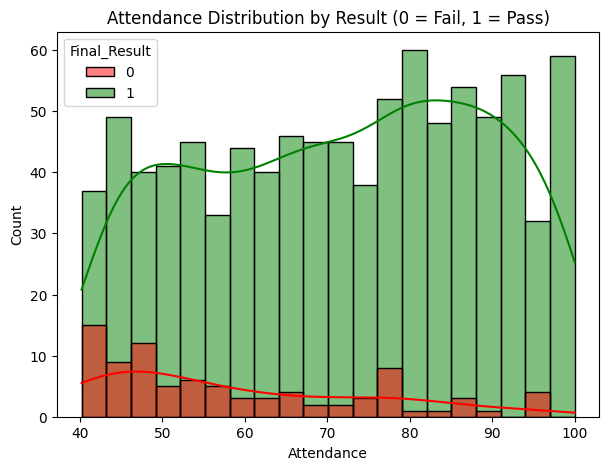

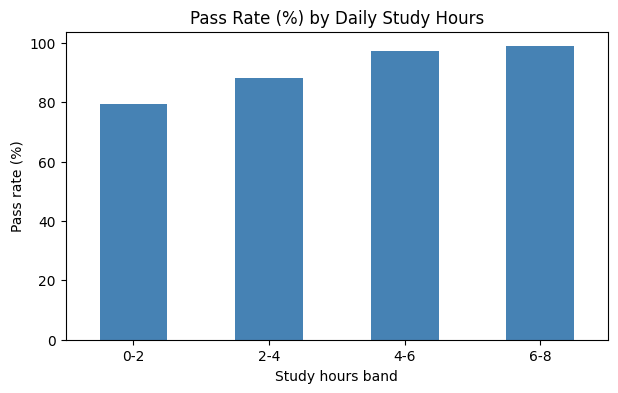

In [25]:
# Study hours vs marks (extra EDA from the synopsis)
plt.figure(figsize=(7, 5))
sns.scatterplot(x="Study_Hours", y="Internal_Marks", hue="Final_Result", data=df_clean, palette={0: "red", 1: "green"})
plt.title("Study Hours vs Internal Marks")
plt.show()

# Attendance vs result
plt.figure(figsize=(7, 5))
sns.histplot(data=df_clean, x="Attendance", hue="Final_Result", bins=20, kde=True, palette={0: "red", 1: "green"})
plt.title("Attendance Distribution by Result (0 = Fail, 1 = Pass)")
plt.show()

# Pass rate per study-hour band
bands = pd.cut(df_clean["Study_Hours"], bins=[0, 2, 4, 6, 8], labels=["0-2", "2-4", "4-6", "6-8"])
df_clean.groupby(bands, observed=True)["Final_Result"].mean().mul(100).plot(kind="bar", color="steelblue", figsize=(7, 4))
plt.title("Pass Rate (%) by Daily Study Hours")
plt.ylabel("Pass rate (%)"); plt.xlabel("Study hours band"); plt.xticks(rotation=0)
plt.show()

## 5. Feature Selection

In [26]:
print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (1000, 5)
y shape: (1000,)


In [27]:
X.head()

,Study_Hours,Attendance,Previous_Marks,Assignments,Internal_Marks
0,3.3,51.1,48.3,73.8,65.8
1,7.6,72.5,47.3,83.7,84.4
2,6.0,92.4,93.4,40.0,80.8
3,5.0,83.9,47.5,70.0,32.3
4,1.7,88.4,49.0,65.7,31.9


Internal_Marks    0.260292
Study_Hours       0.257380
Attendance        0.207016
Previous_Marks    0.174189
Assignments       0.118863
Name: Final_Result, dtype: float64


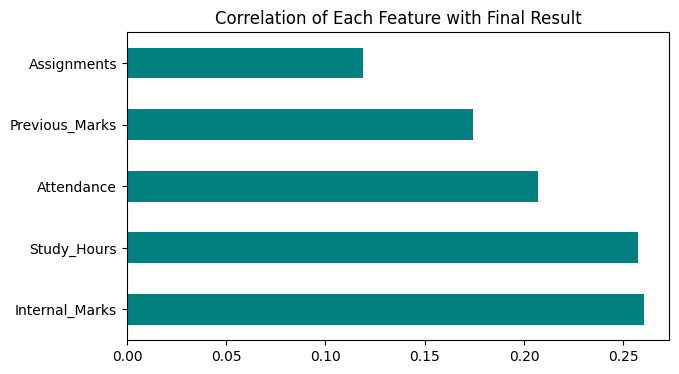

In [28]:
# Feature importance check via correlation with target
corr_target = df_ml.corr()["Final_Result"].drop("Final_Result").sort_values(ascending=False)
print(corr_target)
corr_target.plot(kind="barh", color="teal", figsize=(7, 4))
plt.title("Correlation of Each Feature with Final Result")
plt.show()

## 6. Train/Test Split (80% / 20%) and Normalization

In [29]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print("Training set:", X_train.shape)
print("Testing set :", X_test.shape)

# Normalize numerical values (fit on training data only to avoid data leakage)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

Training set: (800, 5)
Testing set : (200, 5)


## 7. Model Selection and Training
Algorithms: Logistic Regression, Decision Tree, Naive Bayes, SVM (plus Random Forest as an extra).

In [30]:
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import SVC

models = {
    "Logistic Regression": LogisticRegression(max_iter=1000, random_state=42),
    "Decision Tree": DecisionTreeClassifier(max_depth=5, random_state=42),
    "Naive Bayes": GaussianNB(),
    "SVM": SVC(kernel="rbf", probability=True, random_state=42),
    "Random Forest": RandomForestClassifier(n_estimators=200, random_state=42),
}

for name, model in models.items():
    model.fit(X_train_scaled, y_train)
    print(f"{name} trained")

Logistic Regression trained
Decision Tree trained
Naive Bayes trained


SVM trained


Random Forest trained


## 8. Model Testing and Evaluation
Metrics: Accuracy, Precision, Recall, F1-score. For this project, the **Fail class (0)** is what we most care about, but we report standard metrics for Pass (1) as the synopsis defines.

In [31]:
results = []
predictions = {}

for name, model in models.items():
    y_pred = model.predict(X_test_scaled)
    predictions[name] = y_pred
    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred),
        "Recall": recall_score(y_test, y_pred),
        "F1-Score": f1_score(y_test, y_pred),
        "Fail Recall": recall_score(y_test, y_pred, pos_label=0),
    })

results_df = pd.DataFrame(results).sort_values("F1-Score", ascending=False).reset_index(drop=True)
results_df.round(4)

,Model,Accuracy,Precision,Recall,F1-Score,Fail Recall
0,Naive Bayes,0.945,0.9479,0.9945,0.9707,0.4118
1,SVM,0.940,0.9385,1.0000,0.9683,0.2941
2,Random Forest,0.935,0.9381,0.9945,0.9655,0.2941
3,Logistic Regression,0.935,0.9474,0.9836,0.9651,0.4118
4,Decision Tree,0.920,0.9372,0.9781,0.9572,0.2941


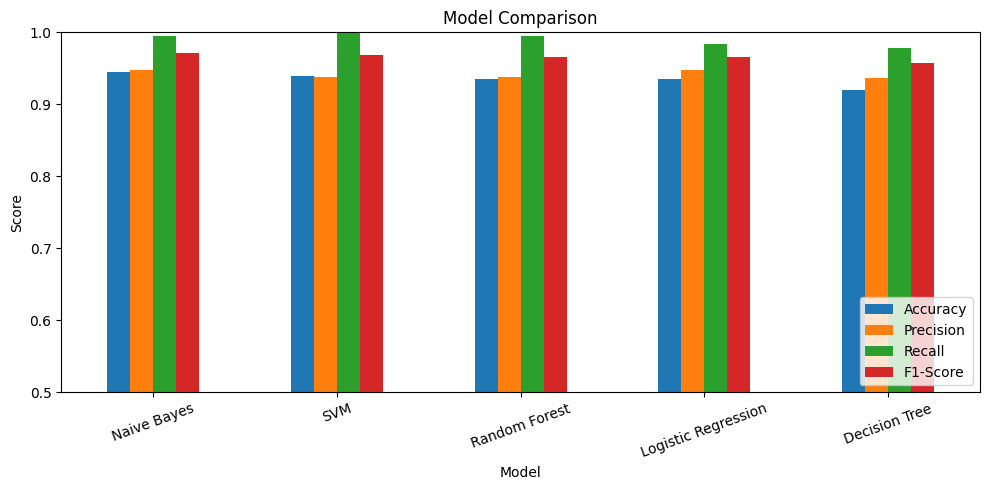

In [32]:
results_df.set_index("Model")[["Accuracy", "Precision", "Recall", "F1-Score"]].plot(
    kind="bar", figsize=(10, 5), ylim=(0.5, 1.0))
plt.title("Model Comparison")
plt.ylabel("Score")
plt.xticks(rotation=20)
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

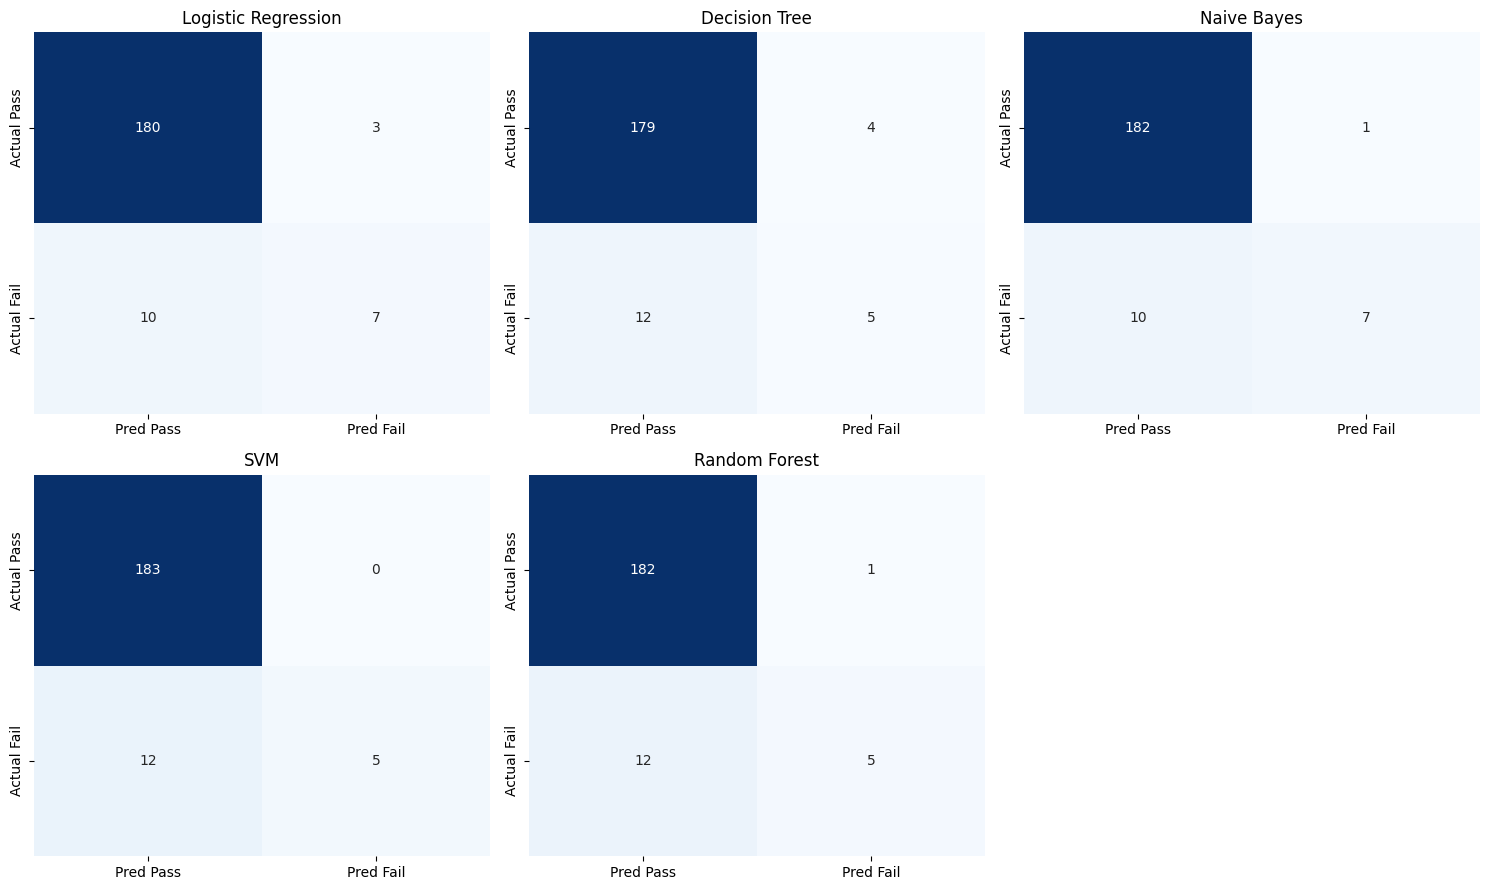

In [33]:
# Confusion matrices (rows = Actual, columns = Predicted)
fig, axes = plt.subplots(2, 3, figsize=(15, 9))
for ax, (name, y_pred) in zip(axes.ravel(), predictions.items()):
    cm = confusion_matrix(y_test, y_pred, labels=[1, 0])
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", ax=ax, cbar=False,
                xticklabels=["Pred Pass", "Pred Fail"], yticklabels=["Actual Pass", "Actual Fail"])
    ax.set_title(name)
axes.ravel()[-1].axis("off")
plt.tight_layout()
plt.show()

In [34]:
best_name = results_df.loc[0, "Model"]
best_model = models[best_name]
print("Best model:", best_name)
print()
print(classification_report(y_test, predictions[best_name], target_names=["Fail", "Pass"]))

Best model: Naive Bayes

              precision    recall  f1-score   support

        Fail       0.88      0.41      0.56        17
        Pass       0.95      0.99      0.97       183

    accuracy                           0.94       200
   macro avg       0.91      0.70      0.77       200
weighted avg       0.94      0.94      0.94       200



## 9. Prediction Module
Predict the result for a new student.

In [35]:
def predict_student(study_hours, attendance, previous_marks, assignments, internal_marks, model=best_model):
    new = pd.DataFrame([[study_hours, attendance, previous_marks, assignments, internal_marks]], columns=X.columns)
    scaled = scaler.transform(new)
    pred = model.predict(scaled)[0]
    prob_pass = model.predict_proba(scaled)[0][1]
    label = "Pass" if pred == 1 else "Fail"
    risk = "AT RISK" if pred == 0 or prob_pass < 0.60 else "Safe"
    print(f"Prediction: {label} | Pass probability: {prob_pass:.1%} | Status: {risk}")
    return label

# Example students
predict_student(6.5, 90, 80, 85, 78)   # strong student
predict_student(1.0, 45, 35, 30, 28)   # weak student
predict_student(3.5, 65, 55, 60, 50)   # average student

Prediction: Pass | Pass probability: 100.0% | Status: Safe
Prediction: Fail | Pass probability: 12.0% | Status: AT RISK
Prediction: Pass | Pass probability: 86.3% | Status: Safe


'Pass'

In [36]:
# Grade prediction (A / B / C / Fail) based on predicted pass probability
def grade_from_prob(p):
    if p >= 0.85: return "A"
    if p >= 0.70: return "B"
    if p >= 0.50: return "C"
    return "Fail"

sample = X.sample(5, random_state=1)
probs = best_model.predict_proba(scaler.transform(sample))[:, 1]
out = sample.copy()
out["Pass_Probability"] = probs.round(3)
out["Predicted_Grade"] = [grade_from_prob(p) for p in probs]
out

,Study_Hours,Attendance,Previous_Marks,Assignments,Internal_Marks,Pass_Probability,Predicted_Grade
507,6.7,72.0,60.7,57.2,21.9,0.990,A
818,0.9,77.5,30.6,85.7,91.1,0.990,A
452,3.7,92.1,69.0,74.2,86.6,0.999,A
368,2.0,50.8,54.0,35.3,33.1,0.310,Fail
242,7.4,86.3,70.8,63.3,80.5,1.000,A


## 10. Result Visualization: At-Risk Students
Students predicted to fail, or with a pass probability below 60%, are flagged as at-risk.

In [37]:
all_scaled = scaler.transform(X)
full = df_clean.copy()
full["Pass_Probability"] = best_model.predict_proba(all_scaled)[:, 1]
full["Predicted_Result"] = np.where(full["Pass_Probability"] >= 0.5, "Pass", "Fail")
full["Predicted_Grade"] = full["Pass_Probability"].apply(grade_from_prob)
full["Actual_Result"] = full["Final_Result"].map({1: "Pass", 0: "Fail"})

at_risk = full[full["Pass_Probability"] < 0.60].sort_values("Pass_Probability")
at_risk_out = at_risk[["Student_ID", "Study_Hours", "Attendance", "Previous_Marks", "Assignments",
                       "Internal_Marks", "Pass_Probability", "Predicted_Result", "Predicted_Grade"]]

print(f"Total students: {len(full)}")
print(f"At-risk students: {len(at_risk_out)} ({len(at_risk_out)/len(full):.1%})")
at_risk_out.head(15)

Total students: 1000
At-risk students: 60 (6.0%)


,Student_ID,Study_Hours,Attendance,Previous_Marks,Assignments,Internal_Marks,Pass_Probability,Predicted_Result,Predicted_Grade
297,STU0298,2.1,46.3,32.6,25.9,32.1,0.157547,Fail,Fail
676,STU0677,1.3,44.9,55.7,33.9,23.8,0.187541,Fail,Fail
66,STU0067,1.6,54.3,44.1,21.2,30.1,0.192364,Fail,Fail
49,STU0050,1.9,41.3,35.7,41.1,36.1,0.198976,Fail,Fail
400,STU0401,1.3,50.0,53.8,25.4,29.9,0.210648,Fail,Fail
10,STU0011,0.7,53.3,32.4,63.9,22.8,0.212557,Fail,Fail
563,STU0564,0.6,56.5,35.1,53.5,23.9,0.216921,Fail,Fail
201,STU0202,1.1,41.5,37.8,60.3,35.7,0.233597,Fail,Fail
283,STU0284,1.2,40.6,33.2,90.6,24.7,0.235823,Fail,Fail
202,STU0203,1.7,41.3,59.6,35.5,30.0,0.240092,Fail,Fail


In [38]:
os.makedirs("outputs", exist_ok=True)
at_risk_out.to_csv("outputs/at_risk_students.csv", index=False)
full.to_csv("outputs/all_predictions.csv", index=False)
print("Saved: outputs/at_risk_students.csv and outputs/all_predictions.csv")

Saved: outputs/at_risk_students.csv and outputs/all_predictions.csv


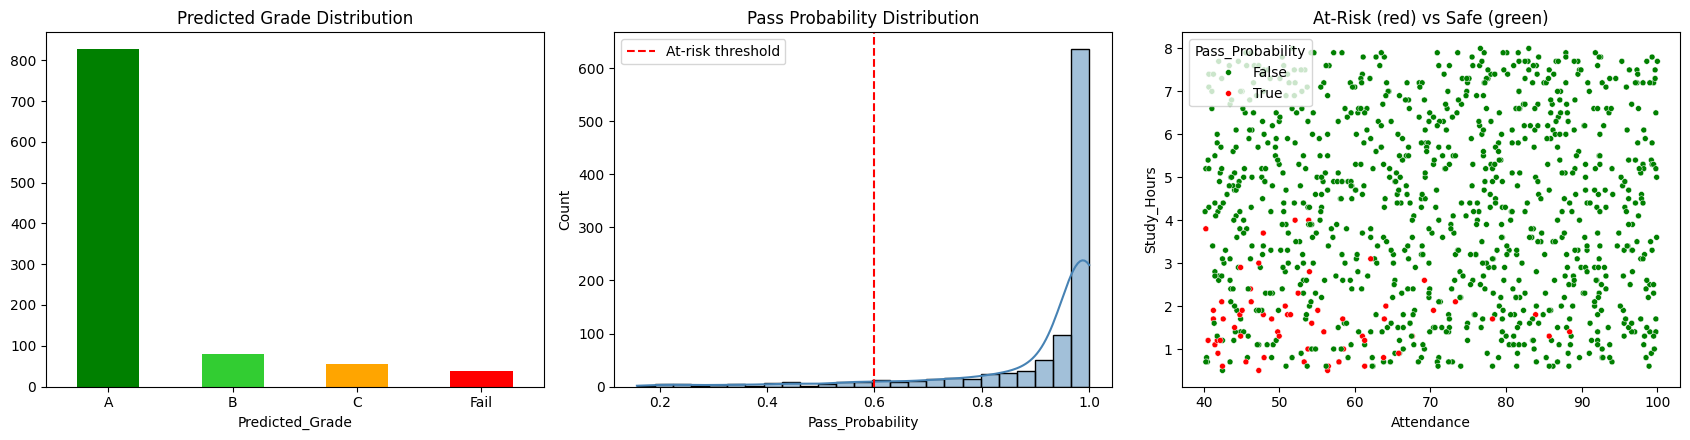

In [39]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))

full["Predicted_Grade"].value_counts().reindex(["A", "B", "C", "Fail"]).plot(kind="bar", color=["green", "limegreen", "orange", "red"], ax=axes[0])
axes[0].set_title("Predicted Grade Distribution"); axes[0].tick_params(axis="x", rotation=0)

sns.histplot(full["Pass_Probability"], bins=25, kde=True, ax=axes[1], color="steelblue")
axes[1].axvline(0.60, color="red", linestyle="--", label="At-risk threshold")
axes[1].set_title("Pass Probability Distribution"); axes[1].legend()

sns.scatterplot(data=full, x="Attendance", y="Study_Hours", hue=full["Pass_Probability"] < 0.60,
                palette={True: "red", False: "green"}, ax=axes[2], s=18)
axes[2].set_title("At-Risk (red) vs Safe (green)")

plt.tight_layout()
plt.show()

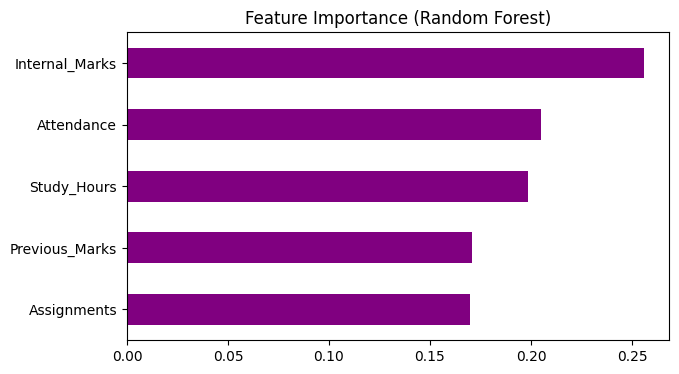

In [40]:
# Which factors matter most? (Random Forest importance + Logistic coefficients)
imp = pd.Series(models["Random Forest"].feature_importances_, index=X.columns).sort_values()
imp.plot(kind="barh", color="purple", figsize=(7, 4))
plt.title("Feature Importance (Random Forest)")
plt.show()

## 11. Save the Trained Model

In [41]:
import joblib
joblib.dump({"model": best_model, "scaler": scaler, "features": list(X.columns)}, "outputs/best_model.joblib")
print(f"Saved best model ({best_name}) to outputs/best_model.joblib")

Saved best model (Naive Bayes) to outputs/best_model.joblib


## 12. Conclusion
- The system predicts Pass/Fail (and an approximate grade) from study hours, attendance, previous marks, assignments and internal marks.
- Five models were trained and compared on accuracy, precision, recall and F1-score; the best one is selected automatically and used for predictions.
- The at-risk list (`outputs/at_risk_students.csv`) lets teachers act early, e.g. extra classes or counselling.

**Limitations:** results depend on data quality, and the model cannot capture emotional or psychological factors. The dataset is synthetic (generated by `generate_dataset.py`).

**Future enhancements:** mobile app, real-time tracking, personalized recommendations, LMS integration.